# G8 — Robustesse d'un modèle (dégradations + évaluation), 100 % sur Kaggle

Ce notebook est **autonome** : il écrit lui-même les fichiers du projet (cellules `%%writefile`), sans GitHub ni zip.

**Réglages AVANT de lancer** (panneau de droite) :
1. **Add Input > Notebooks** : `01_kaggle_data_prep` (vos données converties).
2. **Add Input > Datasets** : le dataset qui contient les poids du modèle choisi (`yolo11_best.pt`, `rtdetr_best.pt` ou `frcnn_best.pth`).
3. **Settings > Accelerator** : GPU T4. **Settings > Internet : On**.
4. **Choisissez le modèle dans la cellule ci-dessous.**

Exécutez les cellules **dans l'ordre**.

In [1]:
MODEL = 'rtdetr'   # 'yolo11' | 'rtdetr' | 'frcnn'
WEIGHTS_FILE = {'yolo11': 'yolo11_best.pt', 'rtdetr': 'rtdetr_best.pt', 'frcnn': 'frcnn_best.pth'}[MODEL]
print(MODEL, WEIGHTS_FILE)

rtdetr rtdetr_best.pt


## 1. Création du projet

In [2]:
import os
REPO = '/kaggle/working/g8-traffic-sign-detection'
for d in ['src/degradations', 'src/evaluation', 'src/models', 'scripts', 'reports', 'weights', 'results']:
    os.makedirs(f'{REPO}/{d}', exist_ok=True)
for d in ['src', 'src/degradations', 'src/evaluation', 'src/models']:
    open(f'{REPO}/{d}/__init__.py', 'a').close()
%cd {REPO}
!pip install -q -U ultralytics pycocotools

/kaggle/working/g8-traffic-sign-detection


## 2. Fichiers du projet (ne rien modifier)

In [3]:
%%writefile src/utils.py
from pathlib import Path
import yaml

ROOT = Path(__file__).resolve().parents[1]


def load_config(path: str | Path = ROOT / "config.yaml") -> dict:
    with open(path, "r", encoding="utf-8") as f:
        return yaml.safe_load(f)


Writing src/utils.py


In [4]:
%%writefile src/models/base.py
"""Contrat commun : tous les modèles exposent la même méthode predict()."""
from abc import ABC, abstractmethod

import numpy as np


class Detector(ABC):
    name: str = "base"
    class_names: list[str] = []

    @abstractmethod
    def predict(self, image: np.ndarray, conf: float = 0.25) -> list[dict]:
        """
        image : tableau BGR (H, W, 3), uint8 (format OpenCV)
        retourne une liste de détections :
          [{"box": (x1, y1, x2, y2), "score": 0.87, "class_id": 2, "label": "mandatory"}, ...]
        coordonnées en pixels de l'image d'entrée.
        """


Writing src/models/base.py


In [17]:
%%writefile src/models/yolo.py
"""Wrapper Ultralytics : sert pour YOLO11 ET RT-DETR."""
import numpy as np

from src.models.base import Detector


class UltralyticsDetector(Detector):
    def __init__(self, weights: str, name: str = "yolo11", kind: str = "yolo",
                 imgsz: int = 1280, iou: float = 0.5, device: str | None = None):
        from ultralytics import RTDETR, YOLO
        self.model = (RTDETR if kind == "rtdetr" else YOLO)(weights)
        self.name, self.imgsz, self.iou, self.device = name, imgsz, iou, device
        self.class_names = list(self.model.names.values())

    def predict(self, image: np.ndarray, conf: float = 0.25) -> list[dict]:
        # Ultralytics considère un ndarray comme BGR (convention OpenCV)
        res = self.model.predict(image, conf=conf, iou=self.iou, imgsz=self.imgsz,
                                 device=self.device, verbose=False)[0]
        b = res.boxes
        if b is None or len(b) == 0:
            return []
        xyxy = b.xyxy.cpu().numpy()          # un seul transfert GPU -> CPU pour toutes les boîtes
        score = b.conf.cpu().numpy()
        cls = b.cls.cpu().numpy().astype(int)
        names = self.model.names
        return [{"box": tuple(float(v) for v in xyxy[i]), "score": float(score[i]),
                 "class_id": int(cls[i]), "label": names[int(cls[i])]} for i in range(len(cls))]


Overwriting src/models/yolo.py


In [6]:
%%writefile src/degradations/degrade.py
"""
Dégradations synthétiques pour tester la robustesse des détecteurs.

    from src.degradations.degrade import apply, KINDS, make_seed
    out = apply(image_bgr, "rain", level=3, seed=make_seed("00012.png", "rain", 3))

- kind  : "rain", "fog", "night", "blur", "occlusion", "jpeg"
- level : 0 (image intacte) puis 1 (léger) -> 5 (très sévère)
- seed  : rend la dégradation REPRODUCTIBLE : tous les modèles voient exactement la même image dégradée.
- boxes : (occlusion seulement) boîtes vérité terrain [(x1, y1, x2, y2), ...] en pixels.
          Les panneaux sont alors recouverts d'une fraction précise de leur surface.

Entrée et sortie : tableau BGR uint8 (H, W, 3), même taille.
"""
from __future__ import annotations

import zlib

import cv2
import numpy as np

KINDS = ["rain", "fog", "night", "blur", "occlusion", "jpeg"]
LEVELS = (1, 2, 3, 4, 5)


def make_seed(name: str, kind: str, level: int) -> int:
    """Graine déterministe (identique d'une machine à l'autre) pour une image donnée."""
    return zlib.crc32(f"{name}|{kind}|{level}".encode()) & 0xFFFFFFFF


# ----------------------------------------------------------------------------- pluie
def _rain(img, level, rng, boxes=None):
    h, w = img.shape[:2]
    density = (3e-4, 6e-4, 1e-3, 1.5e-3, 2.2e-3)[level - 1]   # gouttes par pixel
    length = max(5, int(h * (0.02, 0.03, 0.04, 0.05, 0.06)[level - 1]))
    darken = (0.95, 0.90, 0.85, 0.80, 0.75)[level - 1]          # ciel couvert
    haze = (0.05, 0.10, 0.15, 0.20, 0.25)[level - 1]            # voile gris
    thickness = 1 if level < 4 else 2

    n = int(h * w * density)
    xs, ys = rng.integers(0, w, n), rng.integers(0, h, n)
    vals = rng.integers(170, 256, n)
    slant = np.deg2rad(rng.uniform(-12, 12))                    # même inclinaison pour toutes
    dx, dy = int(length * np.sin(slant)), int(length * np.cos(slant))

    layer = np.zeros((h, w), np.uint8)
    for x, y, v in zip(xs, ys, vals):
        cv2.line(layer, (int(x), int(y)), (int(x) + dx, int(y) + dy), int(v), thickness)
    layer = cv2.GaussianBlur(layer, (3, 3), 0)

    f = img.astype(np.float32) * darken
    f = f * (1 - haze) + 190.0 * haze
    f += layer[..., None].astype(np.float32) * 0.55
    return np.clip(f, 0, 255).astype(np.uint8)


# ------------------------------------------------------------------------- brouillard
def _fog(img, level, rng, boxes=None):
    """Modèle de diffusion atmosphérique : I = J*t + A*(1-t), t = exp(-beta*profondeur)."""
    h, w = img.shape[:2]
    beta = (0.4, 0.8, 1.2, 1.7, 2.3)[level - 1]
    airlight = 215.0
    y = np.linspace(1.0, 0.0, h, dtype=np.float32)[:, None]      # haut = loin, bas = proche
    small = rng.random((h // 64 + 2, w // 64 + 2)).astype(np.float32) - 0.5
    noise = cv2.resize(small, (w, h), interpolation=cv2.INTER_CUBIC)  # nappes de brume
    depth = np.clip(0.6 + 0.4 * y + 0.3 * noise, 0.05, None)
    t = np.exp(-beta * depth)[..., None]
    f = img.astype(np.float32) * t + airlight * (1 - t)
    return np.clip(f, 0, 255).astype(np.uint8)


# ------------------------------------------------------------------------------- nuit
def _night(img, level, rng, boxes=None):
    gamma = (1.3, 1.7, 2.1, 2.6, 3.2)[level - 1]
    gain = (0.8, 0.65, 0.5, 0.4, 0.3)[level - 1]
    sigma = (2, 4, 6, 9, 12)[level - 1]                          # bruit du capteur
    f = (img.astype(np.float32) / 255.0) ** gamma * gain * 255.0
    f *= np.array([1.05, 0.98, 0.90], np.float32)               # teinte bleutée (BGR)
    f += rng.normal(0, sigma, f.shape).astype(np.float32)
    return np.clip(f, 0, 255).astype(np.uint8)


# ------------------------------------------------------------------------ flou de bougé
def _blur(img, level, rng, boxes=None):
    k = (5, 9, 15, 23, 31)[level - 1]                            # longueur du flou en pixels
    angle = rng.uniform(-10, 10)                                 # mouvement quasi horizontal
    kernel = np.zeros((k, k), np.float32)
    kernel[k // 2, :] = 1.0
    m = cv2.getRotationMatrix2D(((k - 1) / 2, (k - 1) / 2), angle, 1.0)
    kernel = cv2.warpAffine(kernel, m, (k, k))
    kernel /= max(float(kernel.sum()), 1e-6)
    return cv2.filter2D(img, -1, kernel, borderType=cv2.BORDER_REFLECT)


# ------------------------------------------------------------------------- occultation
def _fill(out, xa, ya, xb, yb, rng):
    h, w = out.shape[:2]
    xa, xb, ya, yb = max(0, xa), min(w, xb), max(0, ya), min(h, yb)
    if xb <= xa or yb <= ya:
        return
    base = rng.integers(25, 140)                                 # gris foncé à moyen (branche, camion...)
    patch = rng.normal(base, 8, (yb - ya, xb - xa, 1)) + rng.normal(0, 3, (yb - ya, xb - xa, 3))
    out[ya:yb, xa:xb] = np.clip(patch, 0, 255).astype(np.uint8)


def _occlusion(img, level, rng, boxes=None):
    """Avec boxes : chaque panneau est recouvert sur 10/20/30/40/50 % de sa surface,
    depuis un côté choisi au hasard. Sans boxes : patchs aléatoires dans l'image."""
    out = img.copy()
    h, w = img.shape[:2]
    frac = (0.10, 0.20, 0.30, 0.40, 0.50)[level - 1]

    if boxes:
        for x1, y1, x2, y2 in boxes:
            x1, y1, x2, y2 = (int(round(v)) for v in (x1, y1, x2, y2))
            bw, bh = x2 - x1, y2 - y1
            if bw < 2 or bh < 2:
                continue
            side = int(rng.integers(0, 4))                       # 0 haut, 1 bas, 2 gauche, 3 droite
            if side < 2:
                ph = max(1, int(round(bh * frac)))
                ya, yb = (y1, y1 + ph) if side == 0 else (y2 - ph, y2)
                _fill(out, x1, ya, x2, yb, rng)
            else:
                pw = max(1, int(round(bw * frac)))
                xa, xb = (x1, x1 + pw) if side == 2 else (x2 - pw, x2)
                _fill(out, xa, y1, xb, y2, rng)
    else:
        for _ in range(level + 1):
            pw, ph = int(w * rng.uniform(0.05, 0.15)), int(h * rng.uniform(0.05, 0.15))
            x, y = int(rng.integers(0, max(1, w - pw))), int(rng.integers(0, max(1, h - ph)))
            _fill(out, x, y, x + pw, y + ph, rng)
    return out


# ----------------------------------------------------------------------------- JPEG
def _jpeg(img, level, rng, boxes=None):
    quality = (60, 40, 25, 15, 8)[level - 1]
    ok, buf = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, quality])
    return cv2.imdecode(buf, cv2.IMREAD_COLOR)


_FUNCS = {"rain": _rain, "fog": _fog, "night": _night, "blur": _blur,
          "occlusion": _occlusion, "jpeg": _jpeg}


def apply(image: np.ndarray, kind: str, level: int, seed: int = 0, boxes=None) -> np.ndarray:
    """Applique la dégradation `kind` au niveau `level` (0 = image inchangée)."""
    if level == 0:
        return image.copy()
    if kind not in _FUNCS:
        raise ValueError(f"Dégradation inconnue : {kind!r}. Choix : {KINDS}")
    if level not in LEVELS:
        raise ValueError(f"level doit valoir 0 à 5, reçu {level}")
    return _FUNCS[kind](image, level, np.random.default_rng(seed), boxes)


Writing src/degradations/degrade.py


In [18]:
%%writefile src/evaluation/evaluate.py
"""
Évaluation COMMUNE à tous les modèles (YOLO11, RT-DETR, Faster R-CNN).

Même code, mêmes seuils, mêmes images, mêmes dégradations pour tous -> comparaison équitable.

Métriques :
  - map50, map50_95 : pycocotools, détections avec un seuil de confiance très bas (0.001)
  - precision, recall : à un seuil de confiance d'exploitation (0.25) et IoU 0.5, classe respectée
  - mean_conf       : confiance moyenne des détections gardées à 0.25
  - ms_per_image, fps : temps de Detector.predict() au seuil d'exploitation (0.25), hors dégradation
                        et prétraitement. (Au seuil 0.001 le modèle renvoie des centaines de boîtes candidates :
                        ce temps-là est gardé à part dans 'ms_lowconf'.)

Prérequis côté détecteur : predict(image_bgr, conf) -> [{"box": (x1,y1,x2,y2), "score", "class_id"}]
avec class_id de 0 à N-1 (catégorie COCO correspondante = class_id + 1).

Usage :
  python -m src.evaluation.evaluate --model yolo11 --weights weights/yolo11_best.pt \
      --data-dir data/processed/gtsdb_4cls --split test
  python -m src.evaluation.evaluate ... --degradation rain --level 3 --preprocess clahe
"""
from __future__ import annotations

import argparse
import contextlib
import csv
import io
import json
import time
from collections import defaultdict
from pathlib import Path

import cv2
import numpy as np
from tqdm import tqdm

from src.degradations.degrade import apply as degrade_apply
from src.degradations.degrade import make_seed
from src.utils import ROOT


# ----------------------------------------------------------------------------- outils
def _iou(a, b) -> float:
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def _operating_point(gt_by_img, dets_by_img, conf_thr, iou_thr):
    """Précision / rappel / confiance moyenne au seuil conf_thr (appariement glouton, même classe)."""
    tp = fp = n_gt = 0
    scores, tp_scores = [], []
    for img_id, gts in gt_by_img.items():
        n_gt += len(gts)
        dets = sorted((d for d in dets_by_img.get(img_id, []) if d["score"] >= conf_thr),
                      key=lambda d: -d["score"])
        used = [False] * len(gts)
        for d in dets:
            scores.append(d["score"])
            best, best_iou = -1, iou_thr
            for j, g in enumerate(gts):
                if used[j] or g["class_id"] != d["class_id"]:
                    continue
                v = _iou(d["box"], g["box"])
                if v >= best_iou:
                    best, best_iou = j, v
            if best >= 0:
                used[best] = True
                tp += 1
                tp_scores.append(d["score"])
            else:
                fp += 1
    fn = n_gt - tp
    return {
        "precision": tp / (tp + fp) if tp + fp else 0.0,
        "recall": tp / n_gt if n_gt else 0.0,
        "tp": tp, "fp": fp, "fn": fn, "n_gt": n_gt,
        "n_det": len(scores),
        "mean_conf": float(np.mean(scores)) if scores else 0.0,
        "mean_conf_tp": float(np.mean(tp_scores)) if tp_scores else 0.0,
    }


def _coco_map(coco: dict, images: list, dets_json: list):
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    if not dets_json:
        return 0.0, 0.0, {c["name"]: 0.0 for c in coco["categories"]}
    ids = [im["id"] for im in images]
    idset = set(ids)
    gt = COCO()
    gt.dataset = {"images": images, "categories": coco["categories"],
                  "annotations": [a for a in coco["annotations"] if a["image_id"] in idset]}
    with contextlib.redirect_stdout(io.StringIO()):
        gt.createIndex()
        dt = gt.loadRes(dets_json)
        ev = COCOeval(gt, dt, "bbox")
        ev.params.imgIds = ids
        ev.evaluate()
        ev.accumulate()
        ev.summarize()
    names = {c["id"]: c["name"] for c in coco["categories"]}
    per_class = {}
    for k, cid in enumerate(ev.params.catIds):
        p = ev.eval["precision"][0, :, k, 0, 2]        # IoU 0.5, toutes tailles, maxDets 100
        p = p[p > -1]
        per_class[names[cid]] = float(p.mean()) if p.size else float("nan")
    return max(0.0, float(ev.stats[1])), max(0.0, float(ev.stats[0])), per_class


# ----------------------------------------------------------------------- évaluation
def evaluate(detector, images_dir, coco_json, degradation=None, level=0, preprocess=None,
             conf_eval=0.001, conf_op=0.25, iou_thr=0.5, limit=None, warmup=3, progress=True,
             time_at_op=True):
    """Évalue `detector` sur les images de `images_dir` annotées dans `coco_json`.

    degradation / level : dégradation appliquée en mémoire (reproductible, rien n'est écrit sur disque)
    preprocess          : fonction image_bgr -> image_bgr appliquée APRÈS la dégradation (ou None)
    """
    coco = json.loads(Path(coco_json).read_text())
    images = sorted(coco["images"], key=lambda i: i["id"])
    if limit:
        images = images[:limit]
    n_cls = len(coco["categories"])

    gt_by_img = {im["id"]: [] for im in images}
    for a in coco["annotations"]:
        if a["image_id"] in gt_by_img:
            x, y, w, h = a["bbox"]
            gt_by_img[a["image_id"]].append({"box": (x, y, x + w, y + h),
                                             "class_id": a["category_id"] - 1})

    dets_json, dets_by_img, times, times_low = [], defaultdict(list), [], []
    for k, im in enumerate(tqdm(images, disable=not progress, desc="eval")):
        img = cv2.imread(str(Path(images_dir) / im["file_name"]))
        if img is None:
            raise FileNotFoundError(Path(images_dir) / im["file_name"])
        if degradation and level > 0:
            boxes = [g["box"] for g in gt_by_img[im["id"]]]
            img = degrade_apply(img, degradation, level,
                                seed=make_seed(im["file_name"], degradation, level), boxes=boxes)
        if preprocess is not None:
            img = preprocess(img)

        if k == 0:                                    # échauffement GPU (non chronométré)
            for _ in range(warmup):
                detector.predict(img, conf=conf_eval)
                detector.predict(img, conf=conf_op)
        t0 = time.perf_counter()
        dets = detector.predict(img, conf=conf_eval)        # sert au calcul du mAP
        times_low.append(time.perf_counter() - t0)
        if time_at_op:                                      # vitesse « en conditions réelles »
            t0 = time.perf_counter()
            detector.predict(img, conf=conf_op)
            times.append(time.perf_counter() - t0)

        for d in dets:
            if not 0 <= d["class_id"] < n_cls:
                continue
            x1, y1, x2, y2 = d["box"]
            dets_by_img[im["id"]].append({"box": (x1, y1, x2, y2), "score": d["score"],
                                          "class_id": d["class_id"]})
            dets_json.append({"image_id": im["id"], "category_id": d["class_id"] + 1,
                              "bbox": [x1, y1, x2 - x1, y2 - y1], "score": float(d["score"])})

    map50, map50_95, per_class = _coco_map(coco, images, dets_json)
    op = _operating_point(gt_by_img, dets_by_img, conf_op, iou_thr)
    ms_low = 1000 * float(np.mean(times_low))
    ms = 1000 * float(np.mean(times)) if times else ms_low
    return {"n_images": len(images), "map50": map50, "map50_95": map50_95,
            "precision": op["precision"], "recall": op["recall"],
            "mean_conf": op["mean_conf"], "mean_conf_tp": op["mean_conf_tp"],
            "tp": op["tp"], "fp": op["fp"], "fn": op["fn"], "n_gt": op["n_gt"], "n_det": op["n_det"],
            "ms_per_image": ms, "fps": 1000.0 / ms if ms > 0 else 0.0, "ms_lowconf": ms_low,
            "per_class_ap50": per_class}


# ------------------------------------------------------------------- aides CLI / CSV
def load_detector(model: str, weights: str, imgsz: int = 1280):
    if model in ("yolo11", "rtdetr"):
        from src.models.yolo import UltralyticsDetector
        return UltralyticsDetector(weights, name=model, kind="rtdetr" if model == "rtdetr" else "yolo",
                                   imgsz=imgsz)
    if model == "frcnn":
        from src.models.frcnn import FasterRCNNDetector   # écrit par la personne B
        return FasterRCNNDetector(weights)
    raise ValueError(f"Modèle inconnu : {model} (yolo11 | rtdetr | frcnn)")


def get_preprocess(name):
    if name in (None, "", "none"):
        return None
    from src.preprocessing.preprocess import preprocess    # écrit par la personne B
    return lambda im: preprocess(im, name)


CSV_FIELDS = ["model", "preprocess", "degradation", "level", "n_images", "map50", "map50_95",
              "precision", "recall", "mean_conf", "mean_conf_tp", "tp", "fp", "fn", "n_gt", "n_det",
              "ms_per_image", "fps", "per_class_ap50"]


def append_csv(path, row: dict):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    new = not path.exists()
    row = dict(row, per_class_ap50=json.dumps(row.get("per_class_ap50", {})))
    with open(path, "a", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=CSV_FIELDS, extrasaction="ignore")
        if new:
            w.writeheader()
        w.writerow(row)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--model", required=True, choices=["yolo11", "rtdetr", "frcnn"])
    ap.add_argument("--weights", required=True)
    ap.add_argument("--data-dir", default=str(ROOT / "data/processed/gtsdb_4cls"))
    ap.add_argument("--split", default="test")
    ap.add_argument("--degradation", default=None)
    ap.add_argument("--level", type=int, default=0)
    ap.add_argument("--preprocess", default="none")
    ap.add_argument("--imgsz", type=int, default=1280)
    ap.add_argument("--limit", type=int, default=None)
    ap.add_argument("--out", default=None, help="fichier CSV où ajouter le résultat")
    a = ap.parse_args()

    data = Path(a.data_dir)
    det = load_detector(a.model, a.weights, a.imgsz)
    res = evaluate(det, data / "images" / a.split, data / "coco" / f"{a.split}.json",
                   degradation=a.degradation, level=a.level, preprocess=get_preprocess(a.preprocess),
                   limit=a.limit)
    print(f"\n{a.model} | prétraitement={a.preprocess} | dégradation={a.degradation or 'aucune'} "
          f"niveau={a.level} | {res['n_images']} images")
    for k in ["map50", "map50_95", "precision", "recall", "mean_conf", "ms_per_image", "fps"]:
        print(f"  {k:13s}: {res[k]:.3f}")
    print(f"  (vitesse mesurée à conf=0.25 ; à conf=0.001 : {res['ms_lowconf']:.1f} ms/image)")
    print("  AP50 par classe :", {k: round(v, 3) for k, v in res["per_class_ap50"].items()})
    if a.out:
        append_csv(a.out, dict(res, model=a.model, preprocess=a.preprocess,
                               degradation=a.degradation or "clean", level=a.level))


if __name__ == "__main__":
    main()


Overwriting src/evaluation/evaluate.py


In [8]:
%%writefile scripts/preview_degradations.py
"""Mosaïque de contrôle : une image, chaque dégradation (lignes) x niveaux 0 à 5 (colonnes).
Usage : python scripts/preview_degradations.py --data-dir data/processed/gtsdb_4cls
        -> reports/degradations_preview.png"""
import argparse
import json
import sys
from pathlib import Path

import cv2
import numpy as np

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.degradations.degrade import KINDS, apply, make_seed
from src.utils import ROOT

ap = argparse.ArgumentParser()
ap.add_argument("--data-dir", default=str(ROOT / "data/processed/gtsdb_4cls"))
ap.add_argument("--split", default="test")
ap.add_argument("--image", default=None, help="nom du fichier, ex: 00012.png (défaut : 1re image avec panneau)")
ap.add_argument("--out", default=str(ROOT / "reports/degradations_preview.png"))
a = ap.parse_args()

data = Path(a.data_dir)
coco = json.loads((data / "coco" / f"{a.split}.json").read_text())
boxes_by = {}
for an in coco["annotations"]:
    x, y, w, h = an["bbox"]
    boxes_by.setdefault(an["image_id"], []).append((x, y, x + w, y + h))
im = next(i for i in coco["images"] if (i["file_name"] == a.image if a.image else i["id"] in boxes_by))
img = cv2.imread(str(data / "images" / a.split / im["file_name"]))
boxes = boxes_by.get(im["id"], [])

tw, th = 340, 200
rows = []
for kind in KINDS:
    tiles = []
    for level in range(6):
        out = apply(img, kind, level, seed=make_seed(im["file_name"], kind, level), boxes=boxes)
        t = cv2.resize(out, (tw, th), interpolation=cv2.INTER_AREA)
        cv2.putText(t, f"{kind} {level}", (6, 20), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2)
        tiles.append(t)
    rows.append(np.hstack(tiles))
Path(a.out).parent.mkdir(exist_ok=True)
cv2.imwrite(a.out, np.vstack(rows))
print("Mosaïque enregistrée :", a.out, "| image :", im["file_name"])


Writing scripts/preview_degradations.py


In [12]:
%%writefile scripts/run_robustness.py
"""
Balaye toutes les dégradations x niveaux (+ image propre) pour un modèle, avec ou sans prétraitement,
et ajoute une ligne par combinaison dans un CSV. Les combinaisons déjà présentes sont sautées
(on peut donc relancer après une coupure de session Kaggle).

Usage :
  python scripts/run_robustness.py --model yolo11 --weights weights/yolo11_best.pt \
      --data-dir data/processed/gtsdb_4cls --preprocess none clahe --out results/yolo11.csv
"""
import argparse
import csv
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src.degradations.degrade import KINDS
from src.evaluation.evaluate import append_csv, evaluate, get_preprocess, load_detector
from src.utils import ROOT

ap = argparse.ArgumentParser()
ap.add_argument("--model", required=True, choices=["yolo11", "rtdetr", "frcnn"])
ap.add_argument("--weights", required=True)
ap.add_argument("--data-dir", default=str(ROOT / "data/processed/gtsdb_4cls"))
ap.add_argument("--split", default="test")
ap.add_argument("--preprocess", nargs="+", default=["none"])
ap.add_argument("--kinds", nargs="+", default=KINDS)
ap.add_argument("--levels", nargs="+", type=int, default=[1, 2, 3, 4, 5])
ap.add_argument("--imgsz", type=int, default=1280)
ap.add_argument("--limit", type=int, default=None)
ap.add_argument("--out", required=True)
a = ap.parse_args()

done = set()
if Path(a.out).exists():
    with open(a.out, newline="", encoding="utf-8") as f:
        done = {(r["model"], r["preprocess"], r["degradation"], int(r["level"])) for r in csv.DictReader(f)}

data = Path(a.data_dir)
det = load_detector(a.model, a.weights, a.imgsz)
jobs = [("clean", 0)] + [(k, l) for k in a.kinds for l in a.levels]
for pre in a.preprocess:
    pp = get_preprocess(pre)
    for kind, level in jobs:
        if (a.model, pre, kind, level) in done:
            continue
        res = evaluate(det, data / "images" / a.split, data / "coco" / f"{a.split}.json",
                       degradation=None if kind == "clean" else kind, level=level,
                       preprocess=pp, limit=a.limit, progress=False)
        append_csv(a.out, dict(res, model=a.model, preprocess=pre, degradation=kind, level=level))
        print(f"{a.model:7s} {pre:8s} {kind:10s} niv {level}  mAP50={res['map50']:.3f}  "
              f"mAP50-95={res['map50_95']:.3f}  P={res['precision']:.3f}  R={res['recall']:.3f}", flush=True)
print("Terminé ->", a.out)


Overwriting scripts/run_robustness.py


## 3. Récupérer les données de test et les poids
Copie seulement le jeu de test (90 images + annotations COCO) et `yolo11_best.pt`.

In [13]:
import glob, os, shutil

# --- données (sortie du notebook 01) ---
hits = glob.glob('/kaggle/input/**/gtsdb_4cls/coco/test.json', recursive=True)
assert hits, "Données introuvables : ajoutez la sortie de 01_kaggle_data_prepa en Input."
src = os.path.dirname(os.path.dirname(hits[0]))
dst = f'{REPO}/data/processed/gtsdb_4cls'
os.makedirs(dst, exist_ok=True)
shutil.copytree(f'{src}/coco', f'{dst}/coco', dirs_exist_ok=True)
shutil.copytree(f'{src}/images/test', f'{dst}/images/test', dirs_exist_ok=True)
print('test :', len(os.listdir(f'{dst}/images/test')), 'images')      # attendu : 90

# --- poids ---
w = glob.glob(f'/kaggle/input/**/{WEIGHTS_FILE}', recursive=True)
assert w, f"{WEIGHTS_FILE} introuvable : créez un dataset Kaggle avec ce fichier et ajoutez-le en Input."
shutil.copy(w[0], f'{REPO}/weights/{WEIGHTS_FILE}')
print('poids :', w[0])

test : 90 images
poids : /kaggle/input/datasets/salmaazhich/g8-weights-rtdetr/rtdetr_best.pt


## 4. Contrôle visuel des dégradations
Regardez l'image : lignes = dégradations, colonnes = niveaux 0 (intact) à 5.

Mosaïque enregistrée : /kaggle/working/g8-traffic-sign-detection/reports/degradations_preview.png | image : 00030.png


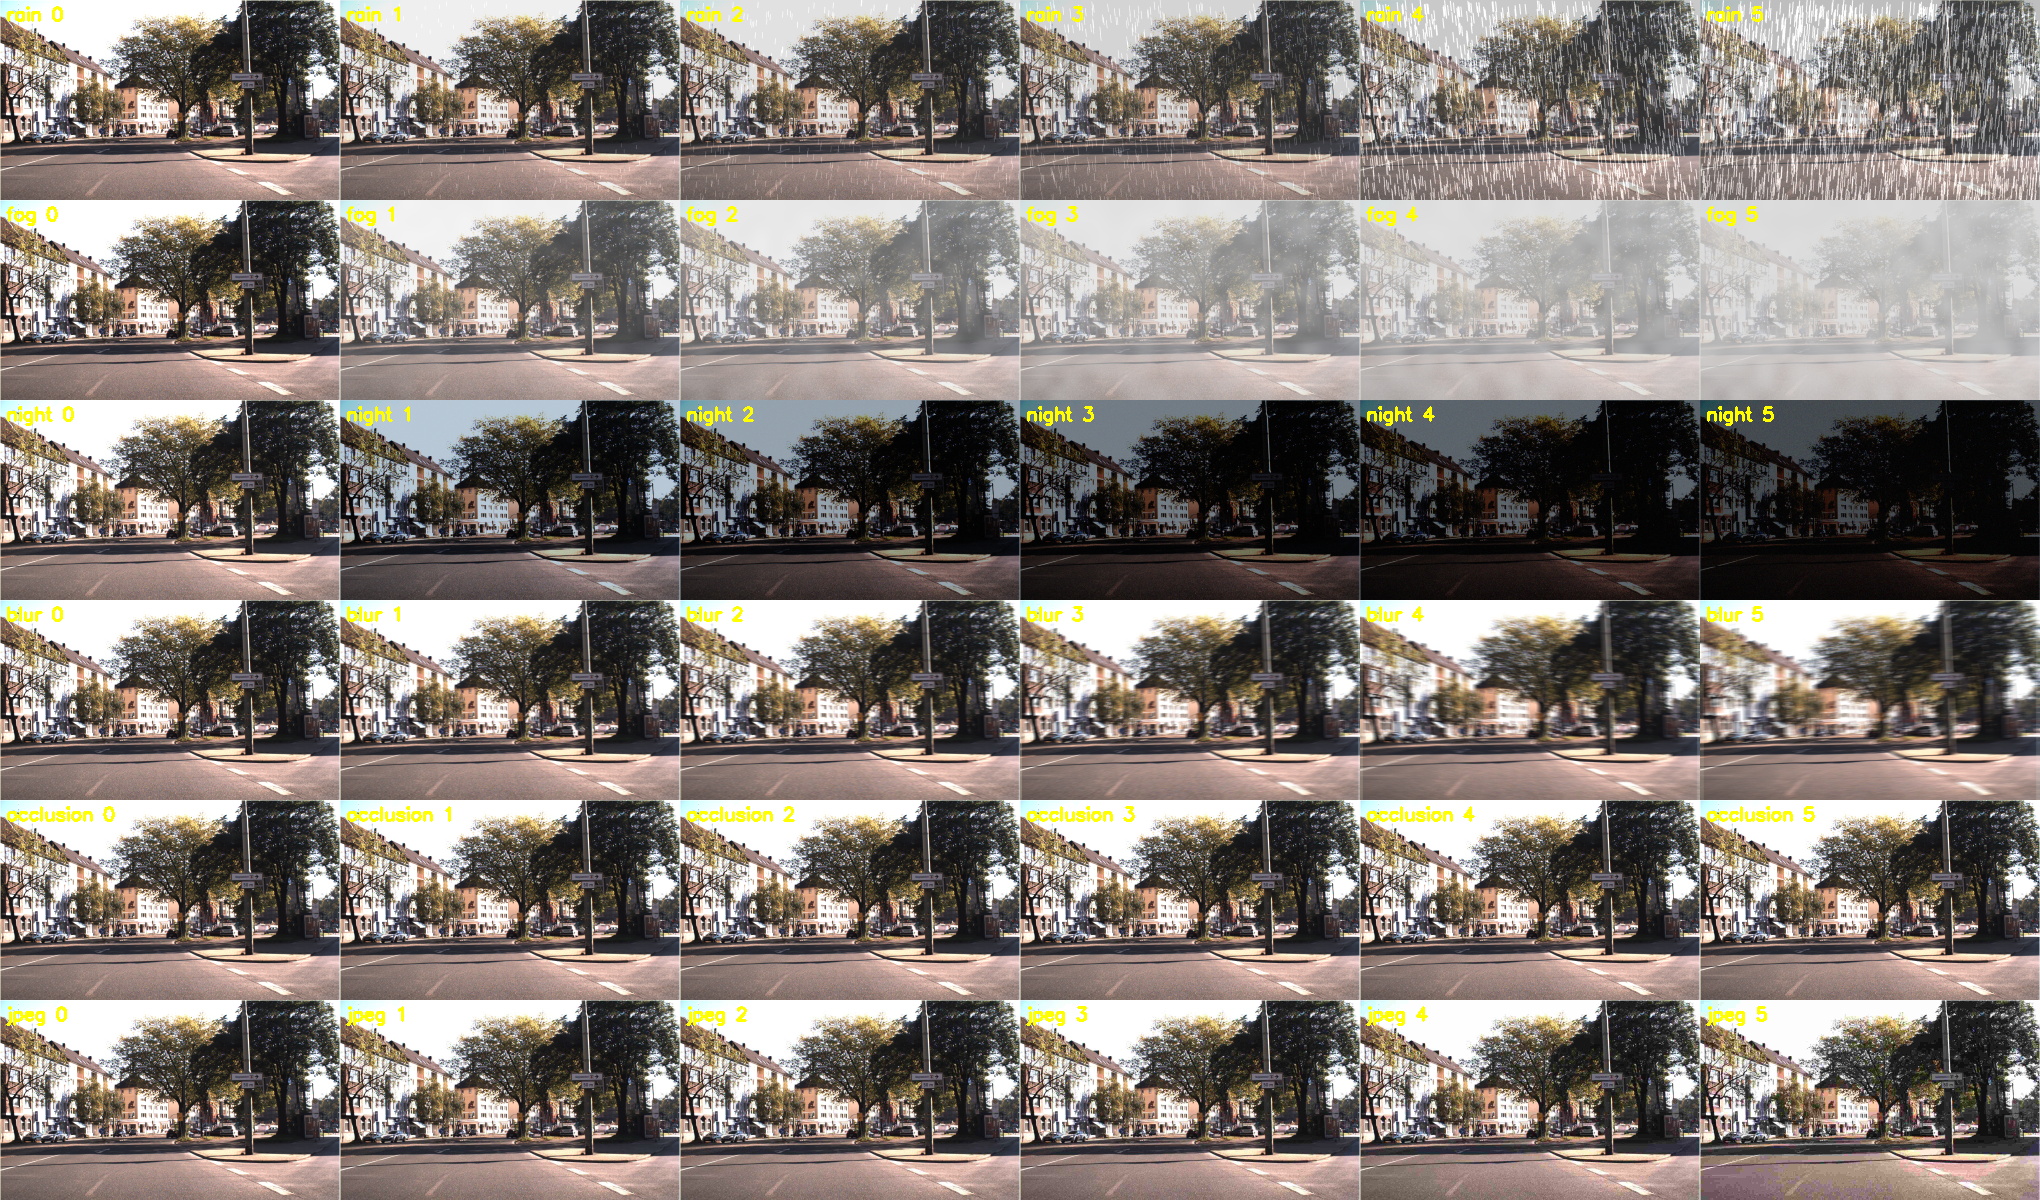

In [14]:
!python scripts/preview_degradations.py --data-dir data/processed/gtsdb_4cls
from IPython.display import Image, display
display(Image('reports/degradations_preview.png'))

## 5. Évaluation sur l'image propre
**Contrôle** : le mAP@0.5 doit être proche de ce que vous aviez trouvé sur le test (≈ 0,99).

In [15]:
!python -m src.evaluation.evaluate --model {MODEL} --weights weights/{WEIGHTS_FILE} --data-dir data/processed/gtsdb_4cls --split test

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
eval: 100%|█████████████████████████████████████| 90/90 [00:29<00:00,  3.07it/s]

rtdetr | prétraitement=none | dégradation=aucune niveau=0 | 90 images
  map50        : 0.997
  map50_95     : 0.894
  precision    : 0.961
  recall       : 0.987
  mean_conf    : 0.920
  ms_per_image : 208.127
  fps          : 4.805
  AP50 par classe : {'prohibitory': 1.0, 'danger': 1.0, 'mandatory': 0.989, 'other': 0.999}


## 6. Balayage complet : 6 dégradations × 5 niveaux (+ image propre)
Quelques minutes sur GPU. Relançable : les combinaisons déjà faites sont sautées.

In [19]:
!python scripts/run_robustness.py --model {MODEL} --weights weights/{WEIGHTS_FILE} --data-dir data/processed/gtsdb_4cls --preprocess none --out /kaggle/working/results/{MODEL}.csv

rtdetr  none     rain       niv 4  mAP50=0.631  mAP50-95=0.484  P=0.986  R=0.473
rtdetr  none     rain       niv 5  mAP50=0.346  mAP50-95=0.236  P=0.897  R=0.173
rtdetr  none     fog        niv 1  mAP50=0.996  mAP50-95=0.895  P=0.968  R=0.993
rtdetr  none     fog        niv 2  mAP50=0.996  mAP50-95=0.890  P=0.974  R=0.993
rtdetr  none     fog        niv 3  mAP50=0.993  mAP50-95=0.883  P=0.980  R=0.967
rtdetr  none     fog        niv 4  mAP50=0.963  mAP50-95=0.842  P=0.966  R=0.960
rtdetr  none     fog        niv 5  mAP50=0.879  mAP50-95=0.741  P=0.960  R=0.800
rtdetr  none     night      niv 1  mAP50=0.992  mAP50-95=0.883  P=0.974  R=0.980
rtdetr  none     night      niv 2  mAP50=0.857  mAP50-95=0.731  P=0.960  R=0.793
rtdetr  none     night      niv 3  mAP50=0.563  mAP50-95=0.458  P=0.986  R=0.473
rtdetr  none     night      niv 4  mAP50=0.282  mAP50-95=0.209  P=0.974  R=0.253
rtdetr  none     night      niv 5  mAP50=0.109  mAP50-95=0.073  P=0.786  R=0.073
rtdetr  none     blur       

## 7. Résultats

mAP@0.5 (image propre) : 0.997 | mAP@0.5:0.95 : 0.894

mAP@0.5 selon la dégradation et le niveau :
level            1      2      3      4      5
degradation                                   
blur         0.962  0.892  0.697  0.463  0.273
fog          0.996  0.996  0.993  0.963  0.879
jpeg         0.982  0.933  0.839  0.631  0.322
night        0.992  0.857  0.563  0.282  0.109
occlusion    0.992  0.958  0.936  0.724  0.425
rain         0.996  0.990  0.923  0.631  0.346

Rappel :
level            1      2      3      4      5
degradation                                   
blur         0.940  0.860  0.593  0.340  0.187
fog          0.993  0.993  0.967  0.960  0.800
jpeg         0.940  0.873  0.633  0.453  0.187
night        0.980  0.793  0.473  0.253  0.073
occlusion    0.987  0.900  0.813  0.540  0.287
rain         0.980  0.980  0.833  0.473  0.173


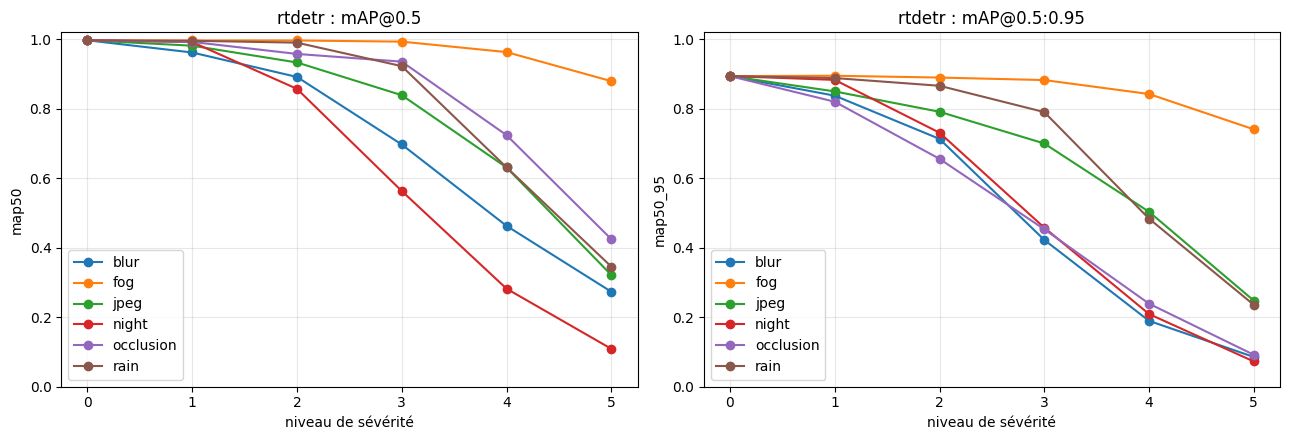

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(f'/kaggle/working/results/{MODEL}.csv')
df = df[df.preprocess == 'none']
clean = df[df.degradation == 'clean'].iloc[0]
deg = df[df.degradation != 'clean']

print('mAP@0.5 (image propre) :', round(clean.map50, 3), '| mAP@0.5:0.95 :', round(clean.map50_95, 3))
print('\nmAP@0.5 selon la dégradation et le niveau :')
print(deg.pivot_table(index='degradation', columns='level', values='map50').round(3))
print('\nRappel :')
print(deg.pivot_table(index='degradation', columns='level', values='recall').round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ['map50', 'map50_95']):
    for kind, g in deg.groupby('degradation'):
        g = g.sort_values('level')
        ax.plot([0] + list(g.level), [clean[col]] + list(g[col]), marker='o', label=kind)
    ax.set_xlabel('niveau de sévérité'); ax.set_ylabel(col); ax.set_ylim(0, 1.02)
    ax.grid(alpha=.3); ax.legend()
axes[0].set_title(f'{MODEL} : mAP@0.5'); axes[1].set_title(f'{MODEL} : mAP@0.5:0.95')
plt.tight_layout(); plt.savefig(f'/kaggle/working/robustness_{MODEL}.png', dpi=120); plt.show()